In [3]:
import sys
sys.path.append("../backend")   # permet d'importer le dossier backend/ml

import numpy as np                  # calculs numériques
import pandas as pd                 # tableaux de données
import matplotlib.pyplot as plt     # graphiques
import seaborn as sns               # graphiques statistiques
from sklearn.metrics import roc_auc_score   # mesure de la qualité d'un score de prédiction

# On réutilise exactement le même code que pour l'entraînement et l'API
from ml.feature_engineering import build_dataset, prepare_invoice_table, TARGET, FEATURE_COLUMNS

CUT = pd.Timestamp("2025-12-31")    # date de coupure T
d = "../database/seed/"             # dossier des CSV
customers = pd.read_csv(d + "customers.csv")
invoices = pd.read_csv(d + "invoices.csv")
payments = pd.read_csv(d + "payments.csv")
# On ne charge PAS ground_truth.csv : le profil caché ne doit jamais servir à modéliser.

ds = build_dataset(customers, invoices, payments, CUT)   # une ligne par facture éligible
labeled = ds[ds[TARGET].notna()]                         # on garde celles dont l'issue est connue
print(ds.shape, labeled.shape)

(18943, 24) (17926, 24)


In [4]:
# Nombre total de valeurs manquantes dans chaque table
print(customers.isna().sum().sum(), invoices.isna().sum().sum(), payments.isna().sum().sum())
# Nombre de doublons d'identifiants (doit être 0)
print(invoices["invoice_id"].duplicated().sum(), payments["payment_id"].duplicated().sum())
# Répartition des statuts de facture
print(invoices["invoice_status"].value_counts())
# Part de valeurs manquantes par variable du modèle
print(labeled[FEATURE_COLUMNS].isna().mean().round(3))

0 0 0
0 0
invoice_status
Paid              18519
Disputed            638
Cancelled           419
Issued              406
Partially Paid       18
Name: count, dtype: int64
invoice_amount_eur                    0.000
payment_terms_days                    0.000
customer_age_months                   0.000
invoice_month                         0.000
invoice_quarter                       0.000
amount_to_credit_limit_ratio          0.000
previous_invoice_count                0.000
previous_late_payment_count           0.000
historical_late_payment_rate          0.089
recent_late_rate_last5                0.089
average_payment_delay                 0.093
median_payment_delay                  0.093
maximum_payment_delay                 0.093
outstanding_balance_eur               0.000
customer_outstanding_invoice_count    0.000
days_since_last_payment               0.092
has_history                           0.000
customer_industry                     0.000
customer_segment                     

will_be_late
0.0    0.67589
1.0    0.32411
Name: proportion, dtype: float64


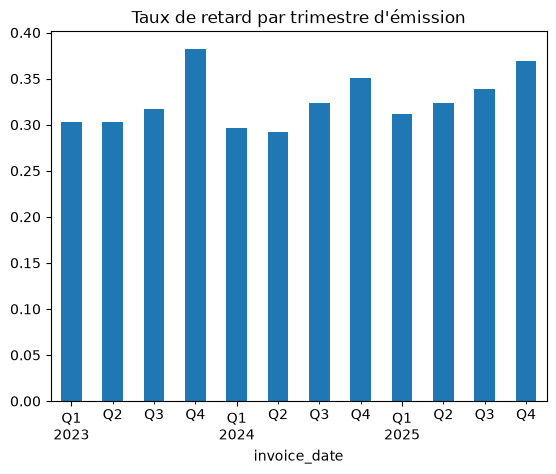

In [5]:
# Proportion de factures à l'heure (0) et en retard (1)
print(labeled[TARGET].value_counts(normalize=True))
# Taux de retard par trimestre d'émission
q = labeled.groupby(labeled["invoice_date"].dt.to_period("Q"))[TARGET].agg(["mean", "count"])
q["mean"].plot(kind="bar", title="Taux de retard par trimestre d'émission")
plt.show()

In [6]:
# Taux de retard (mean) et effectif (count) selon chaque facteur
for col in ["payment_terms_days", "customer_segment", "customer_industry", "has_history"]:
    print(labeled.groupby(col)[TARGET].agg(["mean", "count"]).round(3), "\n")

                     mean  count
payment_terms_days              
15                  0.374   4070
30                  0.332   9473
60                  0.260   4383 

                   mean  count
customer_segment              
Enterprise        0.356   4318
Mid-Market        0.334   5263
SME               0.301   8345 

                    mean  count
customer_industry              
Construction       0.324   2140
Education          0.341   1782
Energy             0.341   1789
Healthcare         0.302   2296
Hospitality        0.326   2141
Logistics          0.284   1937
Manufacturing      0.354   1933
Retail             0.329   2108
Technology         0.322   1800 

              mean  count
has_history              
0            0.326   1600
1            0.324  16326 



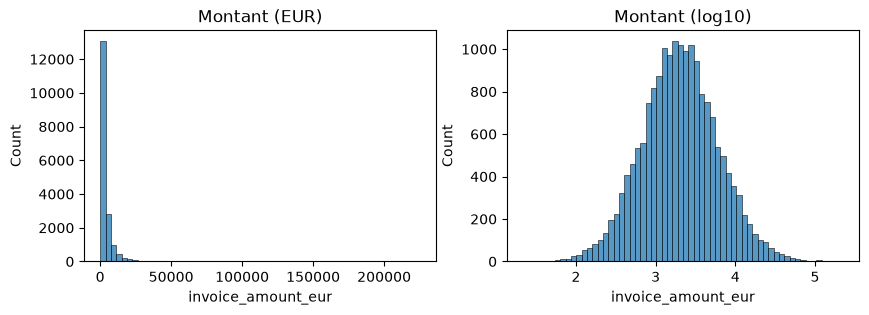

valeurs au-dessus de Q3 + 3 x IQR : 769


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
sns.histplot(labeled["invoice_amount_eur"], bins=60, ax=ax[0]); ax[0].set_title("Montant (EUR)")
sns.histplot(np.log10(labeled["invoice_amount_eur"]), bins=60, ax=ax[1]); ax[1].set_title("Montant (log10)")
plt.show()
# Règle classique : une valeur est extrême si elle dépasse Q3 + 3 x IQR
q1, q3 = labeled["invoice_amount_eur"].quantile([0.25, 0.75])
print("valeurs au-dessus de Q3 + 3 x IQR :", (labeled["invoice_amount_eur"] > q3 + 3 * (q3 - q1)).sum())

In [8]:
# On ne garde que les clients qui ont un historique
h = labeled[labeled["has_history"] == 1]
# AUC : 0,5 = hasard, 1,0 = score parfait
print("AUC du taux historique de retard seul :",
      round(roc_auc_score(h[TARGET], h["historical_late_payment_rate"]), 3))

AUC du taux historique de retard seul : 0.768


In [9]:
inv_t, _ = prepare_invoice_table(customers, invoices, payments, CUT)
# On garde les factures étiquetées qui ont un retard final connu
leak = inv_t[inv_t[TARGET].notna() & inv_t["delay_days"].notna()]
# delay_days est le RÉSULTAT qu'on cherche à prédire : l'utiliser comme variable, c'est tricher
print("AUC avec le retard FINAL de la facture elle-même :",
      round(roc_auc_score(leak[TARGET], leak["delay_days"]), 3))

AUC avec le retard FINAL de la facture elle-même : 1.0
